In [1]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

In [2]:
values = make_array(2,3,3,9)
values

array([2, 3, 3, 9])

In [6]:
average = np.average(values)

In [7]:
sum (values - np.average(values))

0.0

## The standard deviation helps quantify veriability

In [9]:
sd_table = Table().with_columns('value', values)
sd_table

value
2
3
3
9


In [10]:
average_value = np.mean(values)
average_value

4.25

In [11]:
deviations = values - average_value

In [13]:
st_table = sd_table.with_column('deviation', deviations)
sd_table

value
2
3
3
9


In [16]:
np.mean(np.abs(deviations))

2.375

In [17]:
sd_table = sd_table.with_column('Square Deviation', deviations **2)
sd_table

value,Square Deviation
2,5.0625
3,1.5625
3,1.5625
9,22.5625


In [20]:
variance = np.mean(deviations ** 2)
variance

7.6875

### **Standard Deviation**: Root mean squared deviation from average = square root of the variance

In [22]:
sd = variance ** .5
sd

2.7726341266023544

In [23]:
np.std(values)

2.7726341266023544

### Chebyshevs Inequality
no matter what the shape of the distribution the proportion of values are in the range "mean +- Z SD" is at least 1 -1/x^2

z = (values - average)/SD

In [27]:
births = Table.read_table("baby.csv").drop("Maternal Smoker")

In [28]:
births.labels

('Birth Weight',
 'Gestational Days',
 'Maternal Age',
 'Maternal Height',
 'Maternal Pregnancy Weight')

these distributions have different shapes and scales


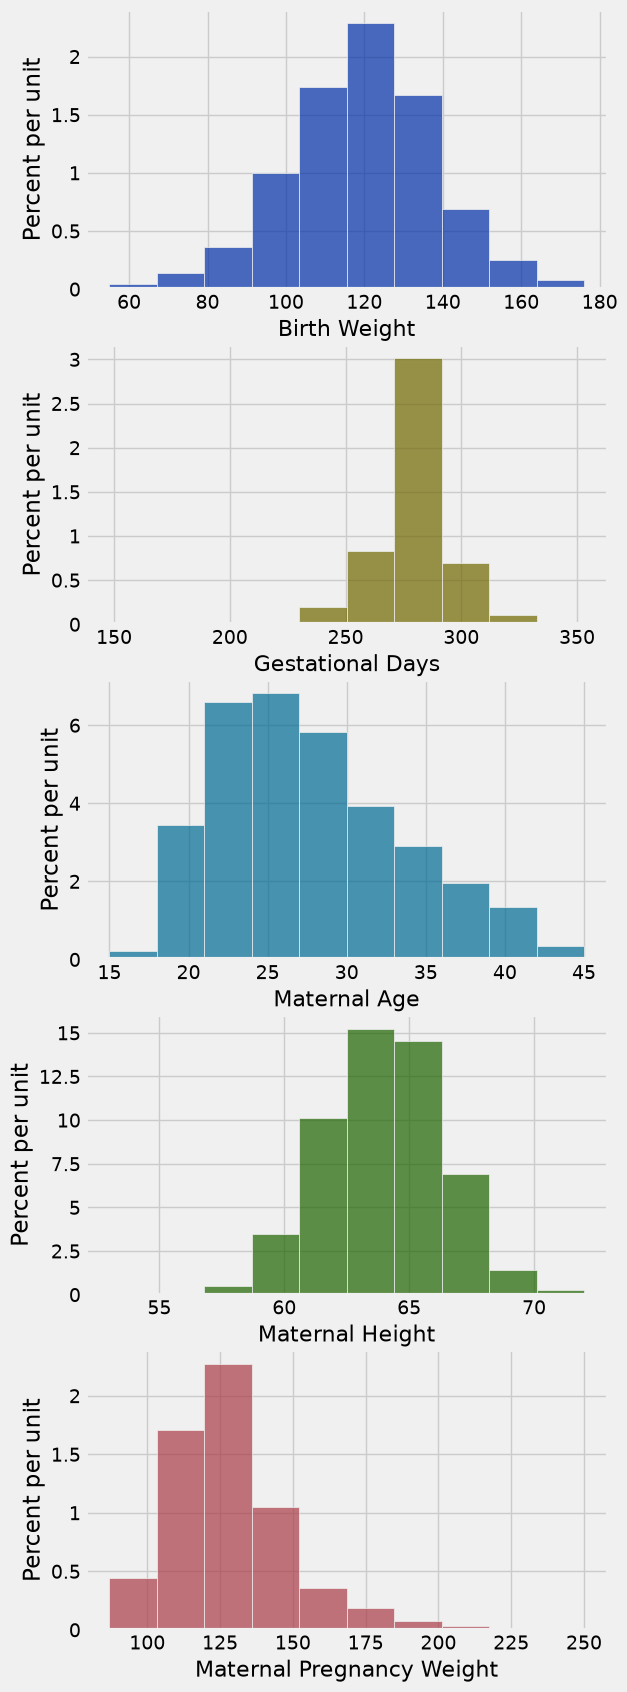

In [32]:
births.hist(overlay = False)
print("these distributions have different shapes and scales")

In [33]:
mpw = births.column('Maternal Pregnancy Weight')
mean = np.mean(mpw)
sd = np.std(mpw)
mean, sd

(128.4787052810903, 20.725449704280411)

In [34]:
within_3_sds = births.where('Maternal Pregnancy Weight', are.between(mean - 3 * sd, mean + 3 * sd))
within_3_sds.num_rows / births.num_rows
                            

0.9863713798977853

## chebychev's inequality

In [36]:
def chebychev(num_sds):
    ''' returns the least proportion of the data in +/- nim_SDs'''
    z = num_sds
    return 1 - 1/(z**2)

In [37]:
chebychev(3)

0.8888888888888888

In [46]:
for feature in births.labels:
    values = births.column(feature)
    mean = np.mean(values)
    sd = np.std(values)
    print()
    print(feature)
    for z in make_array(2, 3, 4, 5):
        chosen = births.where(feature, are.between(mean - z * sd, mean + z * sd))
        proportion = chosen.num_rows / births.num_rows
        percent = round(proportion * 100, 2)
        print('average +=' , z, 'SDs:', percent, '%', ' which is above the chebyschev bound', round(chebychev(z) *100), '%')


Birth Weight
average += 2 SDs: 94.89 %  which is above the chebyschev bound 75 %
average += 3 SDs: 99.57 %  which is above the chebyschev bound 89 %
average += 4 SDs: 100.0 %  which is above the chebyschev bound 94 %
average += 5 SDs: 100.0 %  which is above the chebyschev bound 96 %

Gestational Days
average += 2 SDs: 93.78 %  which is above the chebyschev bound 75 %
average += 3 SDs: 98.64 %  which is above the chebyschev bound 89 %
average += 4 SDs: 99.57 %  which is above the chebyschev bound 94 %
average += 5 SDs: 99.83 %  which is above the chebyschev bound 96 %

Maternal Age
average += 2 SDs: 94.89 %  which is above the chebyschev bound 75 %
average += 3 SDs: 99.91 %  which is above the chebyschev bound 89 %
average += 4 SDs: 100.0 %  which is above the chebyschev bound 94 %
average += 5 SDs: 100.0 %  which is above the chebyschev bound 96 %

Maternal Height
average += 2 SDs: 97.19 %  which is above the chebyschev bound 75 %
average += 3 SDs: 99.66 %  which is above the chebysc

### If a histogram gas a bell shape you may estimate SD!

([<matplotlib.axis.XTick at 0x1a07f2234d0>,
 [Text(57, 0, '57'),
  Text(59, 0, '59'),
  Text(61, 0, '61'),
  Text(63, 0, '63'),
  Text(65, 0, '65'),
  Text(67, 0, '67'),
  Text(69, 0, '69'),
  Text(71, 0, '71')])

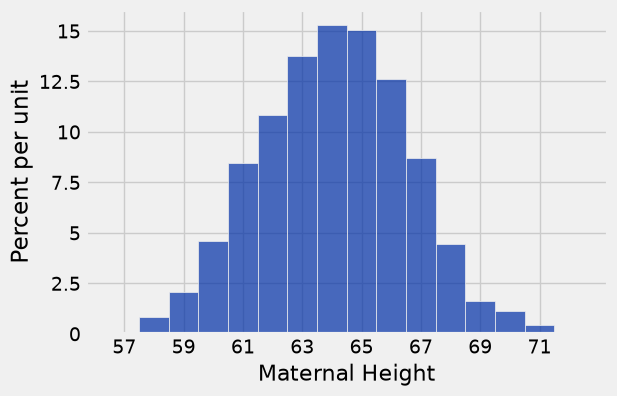

In [51]:
births.hist('Maternal Height', bins = np.arange(56.5, 72.6, 1))
plt.xticks(np.arange(57, 72, 2))

In [72]:
heights = births.column('Maternal Height')
np.mean(heights), np.std(heights)

(64.049403747870528, 2.5250254409674375)

## Conversion to standard units

In [73]:
def standard_units(x):
    return (x - np.mean(x)) / np.std(x)

In [74]:
ages = births.column('Maternal Age')
ages

array([27, 33, 28, ..., 30, 21, 38])

In [76]:
ages_standard_units = standard_units(ages)
ages_standard_units

array([-0.03925456,  0.99249577,  0.13270383, ...,  0.47662061,
       -1.07100488,  1.85228771])

In [78]:
both = Table().with_columns('Age in years', ages, 'Ages in standard units', ages_standard_units)

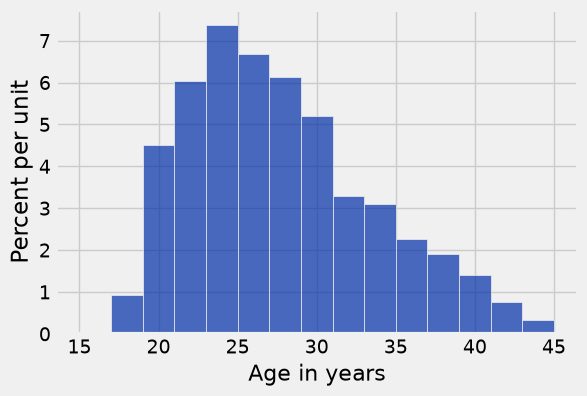

In [79]:
both.hist('Age in years', bins= np.arange(15, 46, 2))

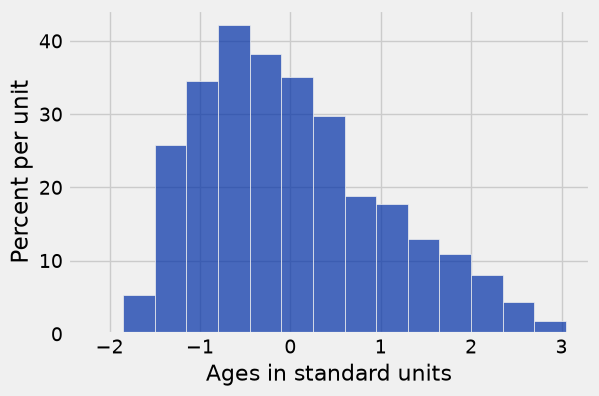

In [84]:
both.hist('Ages in standard units', bins = np.arange(-2.2, 3.4, 0.35))